Dimensões do dataset: 7139 janelas x 20 colunas
Total de valores nulos: 0
Janelas duplicadas: 0

Distribuição dos Comportamentos (Vaca T01):
          Janelas (10s)  Tempo Total (min)  Proporção (%)
behavior                                                 
7                  4468              744.7          62.59
2                  1627              271.2          22.79
3                  1044              174.0          14.62


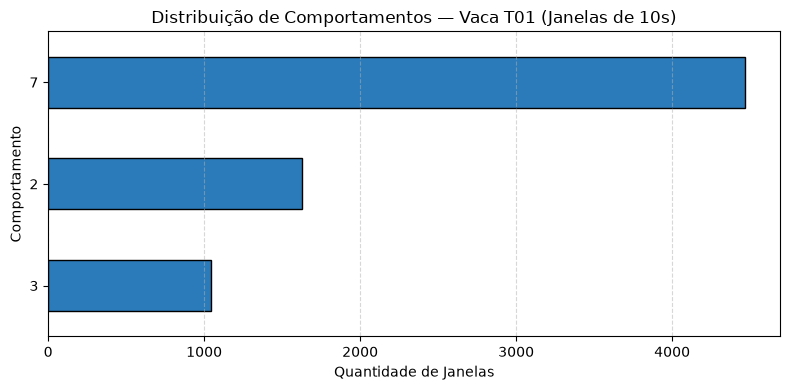

In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Carregar o arquivo limpo da vaca T01
caminho_t01 = os.path.join("./dados/clean", "T01.csv")
df_t01 = pd.read_csv(caminho_t01)

# 2. Auditar formato, nulos e janelas duplicadas
print(f"Dimensões do dataset: {df_t01.shape[0]} janelas x {df_t01.shape[1]} colunas")
print(f"Total de valores nulos: {df_t01.isnull().sum().sum()}")
print(f"Janelas duplicadas: {df_t01['janela'].duplicated().sum()}")

# 3. Montar a tabela com contagem, tempo total e percentual de cada comportamento
contagem = df_t01["behavior"].value_counts()
percentual = (df_t01["behavior"].value_counts(normalize=True) * 100).round(2)

resumo_classes = pd.DataFrame(
    {
        "Janelas (10s)": contagem,
        "Tempo Total (min)": (contagem * 10 / 60).round(1),
        "Proporção (%)": percentual,
    }
)
print("\nDistribuição dos Comportamentos (Vaca T01):")
print(resumo_classes)

# 4. Plotar o gráfico de barras horizontal da distribuição
plt.figure(figsize=(8, 4))
contagem.sort_values().plot(kind="barh", color="#2b7bba", edgecolor="black")
plt.title("Distribuição de Comportamentos — Vaca T01 (Janelas de 10s)")
plt.xlabel("Quantidade de Janelas")
plt.ylabel("Comportamento")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()